In [1]:
import sys
import os

sys.path.append(os.path.abspath(".."))

In [2]:
import kagglehub
import pandas as pd
import os
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from core.logistic_regression import LogisticRegression
import numpy as np
from utils import training, loss
import matplotlib.pyplot as plt
from sklearn.metrics import accuracy_score, confusion_matrix, f1_score

np.random.seed(42)

#### Dataset ophalen en inladen

In [3]:
path = kagglehub.dataset_download("yasserh/breast-cancer-dataset")
file_path = os.path.join(path, 'breast-cancer.csv')

breastcancer = pd.read_csv(file_path)
breastcancer.head()

,id,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,...,radius_worst,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst
0,842302,M,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,...,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,842517,M,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,...,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,84300903,M,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,...,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,84348301,M,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,...,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,84358402,M,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,...,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678


#### Dataset

Alle numerieke kolommen (behalve id) kunnen gebruikt worden als input features, waarbij de kolom 'diagnosis' als target feature fungeert.

De data wordt gesplitst in een train-, validation- en testset met respectievelijk 70%, 15% en 15% van de data.

In [4]:
breastcancer = breastcancer.set_index('id')

input_features = list(breastcancer.columns)
input_features.remove('diagnosis')

# Kolom 'diagnosis' converteren naar numerieke binaire waarden
breastcancer['diagnosis'] = breastcancer['diagnosis'].map({'B':0, 'M':1})

# Pandas dataframes converteren naar np arrays
X = np.array(breastcancer[input_features], dtype=np.float64)
y = np.array(breastcancer['diagnosis'], dtype=np.float64).reshape(-1, 1)

# Dataset splitsen in een train-, validation- en testset.
X_train, X_temp, y_train, y_temp = train_test_split(X, y, test_size=0.3, random_state=42)
X_val, X_test, y_val, y_test = train_test_split(X_temp, y_temp, test_size=0.5, random_state=42)

# Input data normaliseren.
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_val = scaler.transform(X_val)
X_test = scaler.transform(X_test)

print(X_train.shape, y_train.shape)
print(X_val.shape, y_val.shape)
print(X_test.shape, y_test.shape)

(398, 30) (398, 1)
(85, 30) (85, 1)
(86, 30) (86, 1)


#### Trainen

Hyperparameters (epochs en learning rate) en model worden geïnitialiseerd, waarna het model wordt getraind en de gewichten worden opgeslagen.

Epoch    0 | train cost: 0.6899 | validation cost: 0.5890
Epoch   10 | train cost: 0.3294 | validation cost: 0.2953
Epoch   20 | train cost: 0.2525 | validation cost: 0.2248
Epoch   30 | train cost: 0.2157 | validation cost: 0.1901
Epoch   40 | train cost: 0.1931 | validation cost: 0.1687
Epoch   49 | train cost: 0.1789 | validation cost: 0.1552


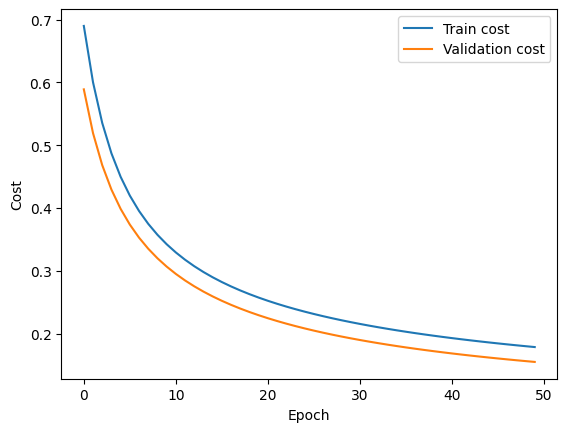

In [5]:
epochs = 50
lr = 0.05
num_features = X_train.shape[1]

model = LogisticRegression(num_features)

model_path = './trained_models/breast_cancer.npz'

train_costs, val_costs = training.model_fit(model, X_train, y_train, 
                                            cost_function=loss.logistic_cost, 
                                            epochs=epochs, lr=lr,
                                            X_val=X_val, y_val=y_val)

model.save(model_path)

plt.plot(train_costs, label="Train cost")
plt.plot(val_costs, label="Validation cost")
plt.xlabel('Epoch')
plt.ylabel('Cost')
plt.legend()
plt.show()

#### Testen

Het model wordt geïnitialiseerd en ingeladen, waarbij het op de testset getest wordt. Het model wordt gevalideerd op de nauwkeurigheid en F1-score en er wordt een confusion matrix gemaakt voor visualisatie van de prestaties.

Accuracy: 98.84%
F1: 0.9811


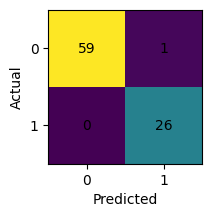

In [6]:
model_path = './trained_models/breast_cancer.npz'

model = LogisticRegression(num_features)
model.load(model_path)
yh = model.forward(X_test)

pred = (yh > 0.5).astype(int)

cm = confusion_matrix(y_test, pred)
plt.figure(figsize=(2, 2))
plt.imshow(cm)
plt.xlabel("Predicted")
plt.ylabel("Actual")

plt.xticks([0, 1])
plt.yticks([0, 1])

for i in range(2):
    for j in range(2):
        plt.text(j, i, cm[i, j],
                 ha="center",
                 va="center")

print(f"Accuracy: {accuracy_score(y_test, pred) * 100:.2f}%")
print("F1:", round(f1_score(y_test, pred), 4))
plt.show()